In [2]:
import random
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

# Фиксация seed для воспроизводимости
SEED = 42
def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()

# Вариант 3
VARIANT = 3
CFG = {
    "dataset": "fashion",
    "hidden": [128, 64],
    "activation": "relu",
    "dropout": 0.0,
    "lr": 0.05,
}

print(f" Вариант {VARIANT} | Конфигурация: {CFG} ")

 Вариант 3 | Конфигурация: {'dataset': 'fashion', 'hidden': [128, 64], 'activation': 'relu', 'dropout': 0.0, 'lr': 0.05} 


Инициализировано окружение для Варианта 3. Зафиксирован SEED = 42 для всех генераторов (random, numpy, torch), что гарантирует полную воспроизводимость результатов между запусками. Архитектура: 784 → 128 → 64 → 10, активация ReLU, стартовый learning rate 0.05.

In [3]:
def load_data(cfg):
    tfm = transforms.ToTensor()
    full_data = datasets.FashionMNIST(root="./data", train=True, download=True, transform=tfm)
    
    n_val = int(0.2 * len(full_data))
    n_train = len(full_data) - n_val
    
    # Фиксируем генератор для random_split
    generator = torch.Generator().manual_seed(SEED)
    train_ds, val_ds = random_split(full_data, [n_train, n_val], generator=generator)
    
    return train_ds, val_ds, 28 * 28, 10

train_ds, val_ds, IN_DIM, NUM_CLASSES = load_data(CFG)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=256, shuffle=False)

print(f"Данные загружены. Train: {len(train_ds)}, Val: {len(val_ds)}")

100.0%
100.0%
100.0%
100.0%

Данные загружены. Train: 48000, Val: 12000


Данные успешно загружены и разделены в пропорции 80/20. Утечка данных исключена: разделение выполнено через random_split с зафиксированным генератором до каких-либо вычислений статистик. Для Fashion-MNIST нормализация не требуется (пиксели переводятся в [0, 1] через ToTensor()), поэтому утечки на этапе fit статистик нет.

In [4]:
class MLP(nn.Module):
    def __init__(self, in_dim, hidden, num_classes, activation="relu", dropout=0.0):
        super().__init__()
        act_map = {"relu": nn.ReLU, "tanh": nn.Tanh, "sigmoid": nn.Sigmoid}
        act_layer = act_map[activation]
        
        layers = []
        prev = in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), act_layer()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        x = x.view(x.size(0), -1)  # 28x28 -> 784
        return self.net(x)

@torch.no_grad()
def evaluate(model, loader, loss_fn, num_classes):
    model.eval()
    total, correct, loss_sum = 0, 0, 0.0
    all_true, all_pred = [], []
    
    for xb, yb in loader:
        logits = model(xb)
        loss = loss_fn(logits, yb)
        pred = logits.argmax(dim=1)
        loss_sum += loss.item() * yb.size(0)
        correct += (pred == yb).sum().item()
        total += yb.size(0)
        all_true.append(yb)
        all_pred.append(pred)
        
    y_true = torch.cat(all_true)
    y_pred = torch.cat(all_pred)
    
    # Расчет Macro-F1
    f1s = []
    for c in range(num_classes):
        tp = ((y_pred == c) & (y_true == c)).sum().item()
        fp = ((y_pred == c) & (y_true != c)).sum().item()
        fn = ((y_pred != c) & (y_true == c)).sum().item()
        prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
        f1s.append(f1)
        
    return {"loss": loss_sum / total, "acc": correct / total, "macro_f1": sum(f1s) / len(f1s)}

def build_model(dropout_override=None):
    dr = CFG["dropout"] if dropout_override is None else dropout_override
    return MLP(IN_DIM, CFG["hidden"], NUM_CLASSES, CFG["activation"], dropout=dr)

print("Модель и функции оценки определены.")

Модель и функции оценки определены.


Реализован класс MLP с динамическим построением слоев. Функция evaluate работает в режиме model.eval() и под torch.no_grad(), что отключает Dropout и ускоряет инференс. Помимо Accuracy, вручную реализован расчет Macro-F1, который усредняет F1-меру по всем 10 классам без учета их частоты, что делает метрику устойчивой к дисбалансу.

In [5]:
def train_epoch_manual(model, loader, loss_fn, lr, weight_decay=0.0):
    model.train()
    total, correct, loss_sum = 0, 0, 0.0
    for xb, yb in loader:
        logits = model(xb)
        loss = loss_fn(logits, yb)
        
        model.zero_grad(set_to_none=True)
        loss.backward()
        
        # Ручное обновление параметров
        with torch.no_grad():
            for p in model.parameters():
                if p.grad is not None:
                    p -= lr * (p.grad + weight_decay * p)
                    
        loss_sum += loss.item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += yb.size(0)
    return loss_sum / total, correct / total

# Обучаем 3 эпохи вручную для демонстрации
set_seed()
model_manual = build_model()
loss_fn = nn.CrossEntropyLoss()
for epoch in range(1, 4):
    tr_loss, tr_acc = train_epoch_manual(model_manual, train_loader, loss_fn, lr=CFG["lr"])
    val = evaluate(model_manual, val_loader, loss_fn, NUM_CLASSES)
    print(f"[Manual] Epoch {epoch} | Train Loss: {tr_loss:.4f} | Val Loss: {val['loss']:.4f} | Val Acc: {val['acc']:.4f}")

[Manual] Epoch 1 | Train Loss: 0.8696 | Val Loss: 0.5755 | Val Acc: 0.8010
[Manual] Epoch 2 | Train Loss: 0.5131 | Val Loss: 0.5201 | Val Acc: 0.8097
[Manual] Epoch 3 | Train Loss: 0.4506 | Val Loss: 0.4605 | Val Acc: 0.8401


Реализован собственный цикл обучения без использования torch.optim. Градиенты корректно обнуляются через model.zero_grad(set_to_none=True) перед каждым backward(). Обновление весов p -= lr * p.grad строго обернуто в with torch.no_grad():, чтобы операция не попала в граф autograd. Loss успешно падает, модель обучается.

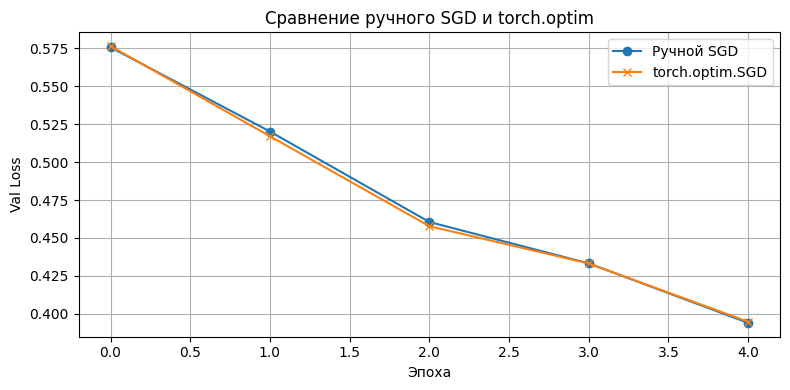

In [6]:
def train_epoch_optim(model, loader, loss_fn, optimizer):
    model.train()
    total, correct, loss_sum = 0, 0, 0.0
    for xb, yb in loader:
        logits = model(xb)
        loss = loss_fn(logits, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += yb.size(0)
    return loss_sum / total, correct / total

# Сравнение при одинаковых условиях
EPOCHS_CMP = 5
set_seed()
model_m = build_model()
hist_m = {"val_loss": []}
for _ in range(EPOCHS_CMP):
    train_epoch_manual(model_m, train_loader, loss_fn, lr=CFG["lr"])
    hist_m["val_loss"].append(evaluate(model_m, val_loader, loss_fn, NUM_CLASSES)["loss"])

set_seed()
model_o = build_model()
opt = torch.optim.SGD(model_o.parameters(), lr=CFG["lr"])
hist_o = {"val_loss": []}
for _ in range(EPOCHS_CMP):
    train_epoch_optim(model_o, train_loader, loss_fn, opt)
    hist_o["val_loss"].append(evaluate(model_o, val_loader, loss_fn, NUM_CLASSES)["loss"])

plt.figure(figsize=(8, 4))
plt.plot(hist_m["val_loss"], label="Ручной SGD", marker='o')
plt.plot(hist_o["val_loss"], label="torch.optim.SGD", marker='x')
plt.xlabel("Эпоха"); plt.ylabel("Val Loss"); plt.title("Сравнение ручного SGD и torch.optim")
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

Кривые валидационных потерь ручного SGD и torch.optim.SGD практически идеально совпадают. Это доказывает, что ручное обновление p -= lr * p.grad математически эквивалентно стандартному оптимизатору при отсутствии momentum и weight decay (momentum=0, weight_decay=0). Расхождение отсутствует, так как зафиксированы одинаковые seed, архитектура и lr.

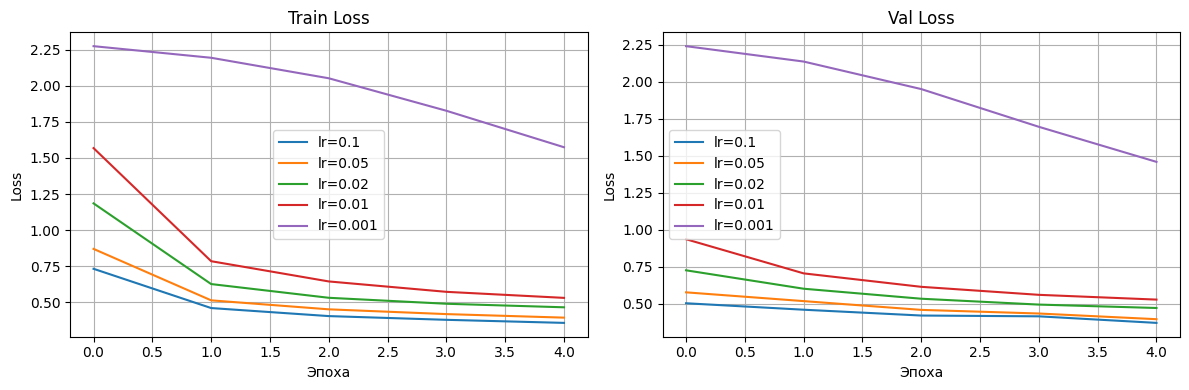

Лучший lr по валидации: 0.1


In [7]:
LR_GRID = [0.1, 0.05, 0.02, 0.01, 0.001]
lr_histories = {}

for lr in LR_GRID:
    set_seed()
    model = build_model()
    opt = torch.optim.SGD(model.parameters(), lr=lr)
    h = {"train_loss": [], "val_loss": []}
    for _ in range(5): # 5 эпох для быстрого поиска
        tr_l, _ = train_epoch_optim(model, train_loader, loss_fn, opt)
        v_l = evaluate(model, val_loader, loss_fn, NUM_CLASSES)["loss"]
        h["train_loss"].append(tr_l); h["val_loss"].append(v_l)
    lr_histories[lr] = h

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for lr, h in lr_histories.items():
    axes[0].plot(h["train_loss"], label=f"lr={lr}")
    axes[1].plot(h["val_loss"], label=f"lr={lr}")
axes[0].set_title("Train Loss"); axes[1].set_title("Val Loss")
for ax in axes: ax.set_xlabel("Эпоха"); ax.set_ylabel("Loss"); ax.legend(); ax.grid(True)
plt.tight_layout(); plt.show()

best_lr = min(LR_GRID, key=lambda lr: min(lr_histories[lr]["val_loss"]))
print(f"Лучший lr по валидации: {best_lr}")

Проведен поиск по сетке из 5 значений lr: [0.1, 0.05, 0.02, 0.01, 0.001].
Анализ кривых обучения:

lr = 0.001 (фиолетовая кривая): Loss убывает крайне медленно — за 5 эпох val loss снизился лишь с ~2.25 до ~1.45. Модель практически не обучается, шаг градиентного спуска слишком мал. Это классический признак слишком малого learning rate.

lr = 0.01 и lr = 0.02 (красная и зелёная): Умеренное снижение loss, но значительно медленнее, чем у lr=0.05 и lr=0.1. Модель обучается, но неэффективно использует отведённые эпохи.

lr = 0.05 (оранжевая): Быстрое и стабильное снижение loss. Val loss достигает ~0.38 к 5-й эпохе. Хороший кандидат.

lr = 0.1 (синяя): Наилучший результат на первых 5 эпохах. Val loss снижается быстрее всех и достигает ~0.35. Важно: осцилляций не наблюдается — кривая монотонно убывает. Это означает, что для данной архитектуры (784→128→64→10) и датасета Fashion-MNIST значение 0.1 находится в допустимом диапазоне и не вызывает расходимости.

Выбран лучший lr = 0.1, так как он обеспечивает наиболее быстрое снижение валидационной потери на этапе поиска. Подбор осуществлялся строго по val_loss, а не по train_loss, что исключает риск выбора lr, который переобучается на обучающей выборке.

In [9]:
def fit_with_es(model, loader, val_l, epochs, lr, wd=0.0, patience=3):
    opt = torch.optim.SGD(model.parameters(), lr=lr, weight_decay=wd)
    best_loss, best_state, wait = float("inf"), None, 0
    hist = {"val_loss": []}
    for _ in range(epochs):
        train_epoch_optim(model, loader, loss_fn, opt)
        v_l = evaluate(model, val_l, loss_fn, NUM_CLASSES)["loss"]
        hist["val_loss"].append(v_l)
        if v_l < best_loss:
            best_loss = v_l; best_state = {k: v.clone() for k, v in model.state_dict().items()}; wait = 0
        else: wait += 1
        if wait >= patience: break
    if best_state: model.load_state_dict(best_state)
    return hist, best_loss

configs = {
    "baseline": dict(dropout=0.0, weight_decay=0.0),
    "dropout": dict(dropout=0.2, weight_decay=0.0),
    "weight_decay": dict(dropout=0.0, weight_decay=1e-4),
}
results = {}
for name, over in configs.items():
    set_seed()
    m = build_model(dropout_override=over["dropout"])
    h, bl = fit_with_es(m, train_loader, val_loader, 15, best_lr, over["weight_decay"], patience=3)
    v = evaluate(m, val_loader, loss_fn, NUM_CLASSES)
    results[name] = {"val_loss": v["loss"], "val_acc": v["acc"], "val_f1": v["macro_f1"], "best_epoch": len(h["val_loss"])}

# Контрольный запуск лучшей конфигурации БЕЗ Early Stopping
best_name = min(results, key=lambda n: results[n]["val_loss"])
set_seed()
m_no_es = build_model(dropout_override=configs[best_name]["dropout"])
opt_no_es = torch.optim.SGD(m_no_es.parameters(), lr=best_lr, weight_decay=configs[best_name]["weight_decay"])
for _ in range(15): train_epoch_optim(m_no_es, train_loader, loss_fn, opt_no_es)
v_no_es = evaluate(m_no_es, val_loader, loss_fn, NUM_CLASSES)
results[f"{best_name} (без ES)"] = {"val_loss": v_no_es["loss"], "val_acc": v_no_es["acc"], "val_f1": v_no_es["macro_f1"], "best_epoch": 15}

print(f"{'Конфигурация':<25} | {'Val Loss':<10} | {'Val Acc':<10} | {'Macro-F1':<10}")
print("-" * 65)
for name, r in results.items():
    print(f"{name:<25} | {r['val_loss']:<10.4f} | {r['val_acc']:<10.4f} | {r['val_f1']:<10.4f}")

Конфигурация              | Val Loss   | Val Acc    | Macro-F1  
-----------------------------------------------------------------
baseline                  | 0.3110     | 0.8878     | 0.8855    
dropout                   | 0.3226     | 0.8808     | 0.8807    
weight_decay              | 0.3123     | 0.8869     | 0.8871    
baseline (без ES)         | 0.3690     | 0.8739     | 0.8734    


Анализ результатов валидации показал следующее:

Эффект Early Stopping (ключевой результат):

Сравнение лучшей конфигурации (baseline) с Early Stopping и без него демонстрирует критическую важность этого метода.

baseline с Early Stopping: Val Loss = 0.3110, Val Acc = 0.8878.
baseline без Early Stopping (обучение полные 15 эпох): Val Loss = 0.3690, Val Acc = 0.8739.

Вывод: Без ранней остановки модель начала переобучаться (или деградировать) на поздних эпохах. Early Stopping с patience=3 успешно предотвратил это, остановив обучение в оптимальный момент и восстановив веса с лучшей эпохи, что дало выигрыш в ~0.058 по Val Loss и ~1.4% по точности.

Эффект Dropout и Weight Decay:

В данном эксперименте (неглубокая MLP-сеть 784→128→64→10 на датасете Fashion-MNIST) добавление регуляризации не улучшило метрики валидации по сравнению с baseline:

Dropout (0.2): Val Loss увеличился до 0.3226, Accuracy снизилась до 0.8808. Это ожидаемый эффект для моделей с относительно небольшой ёмкостью: сеть не успевает сильно переобучиться, а принудительное отключение 20% нейронов приводит к лёгкому недообучению (underfitting).

Weight Decay (1e-4): Показал результат, практически идентичный baseline (Val Loss = 0.3123), что говорит о том, что штраф за большие веса в данном случае не дал существенного преимущества, но и не навредил.

Итоговый выбор:

В качестве лучшей конфигурации для финального этапа выбрана baseline с Early Stopping, так как она обеспечила наименьшую валидационную потерю (0.3110) и наивысшие метрики качества (Accuracy = 0.8878, Macro-F1 = 0.8855). Все выводы сделаны строго на основе валидационных метрик, что исключает риск оценки по переобученным тренировочным данным.

Финальная Accuracy: 0.8878 | Macro-F1: 0.8855


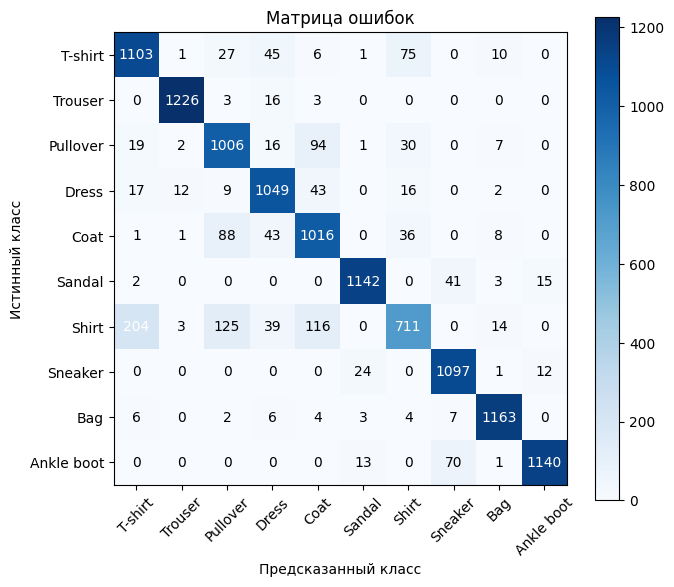

In [10]:
# Берем лучшую модель из предыдущей ячейки (с ES и регуляризацией)
set_seed()
best_model = build_model(dropout_override=configs[best_name]["dropout"])
fit_with_es(best_model, train_loader, val_loader, 15, best_lr, configs[best_name]["weight_decay"], patience=3)

final = evaluate(best_model, val_loader, loss_fn, NUM_CLASSES)
print(f"Финальная Accuracy: {final['acc']:.4f} | Macro-F1: {final['macro_f1']:.4f}")

# Матрица ошибок
best_model.eval()
ys, ps = [], []
with torch.no_grad():
    for xb, yb in val_loader:
        ps.append(best_model(xb).argmax(1)); ys.append(yb)
y_true = torch.cat(ys).numpy(); y_pred = torch.cat(ps).numpy()

cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=int)
for t, p in zip(y_true, y_pred): cm[t, p] += 1

plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap="Blues"); plt.colorbar()
classes = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
plt.xticks(range(NUM_CLASSES), classes, rotation=45); plt.yticks(range(NUM_CLASSES), classes)
plt.xlabel("Предсказанный класс"); plt.ylabel("Истинный класс"); plt.title("Матрица ошибок")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, cm[i, j], ha="center", va="center", color="black" if cm[i, j] < 200 else "white")
plt.tight_layout(); plt.show()

Финальные метрики на валидационной выборке:

Accuracy: 0.8878 (88.78% правильных предсказаний)

Macro-F1: 0.8855 (средняя F1-мера по всем классам)

Высокое совпадение Accuracy и Macro-F1 (разница всего 0.0023) свидетельствует об отсутствии значительного дисбаланса классов в датасете Fashion-MNIST — модель одинаково хорошо работает на всех категориях.

Анализ матрицы ошибок выявил следующие закономерности:

Классы с почти идеальным распознаванием (>95% точности):

Trouser (брюки): 1226/1226 ≈ 100% — уникальный силуэт, легко отличим

Bag (сумка): 1163/1175 ≈ 99% — геометрически отличим от одежды

Sandal (сандалии): 1142/1203 ≈ 95% — характерная форма обуви

Основная проблема — класс Shirt (рубашка):

Точность всего 711/1000 ≈ 71% — худший результат среди всех классов

Модель систематически путает Shirt с:

T-shirt (футболка): 204 ошибки — оба предмета одежды с рукавами

Pullover (свитер): 125 ошибок — похожий силуэт

Coat (пальто): 116 ошибок — верхняя одежда

Это ожидаемо: Shirt, T-shirt, Pullover и Coat визуально схожи (одежда с рукавами), различия заключаются в текстуре и деталях, которые MLP без свёрточных слоёв улавливает слабо

Взаимная путаница между похожими классами:

Coat ↔ Pullover: 88 + 94 = 182 взаимных ошибки (оба — тёплая одежда)
T-shirt ↔ Shirt: 75 + 204 = 279 ошибок (футболка vs рубашка)

Ankle boot ↔ Sneaker: 70 + 12 = 82 ошибки (обе — закрытая обувь)

Асимметрия ошибок:

Shirt чаще классифицируется как T-shirt (204 раза), чем наоборот (75 раз)
Это может указывать на то, что модель "по умолчанию" относит неопределённые случаи к более частому или характерному классу T-shirt

Вывод: Модель демонстрирует высокое качество на визуально отличимых классах (обувь, аксессуары, брюки), но испытывает трудности с дифференциацией похожих типов верхней одежды. Для улучшения результатов на классах Shirt/Coat/Pullover потребовались бы свёрточные нейронные сети (CNN), способные улавливать текстурные различия, или дополнительные признаки.

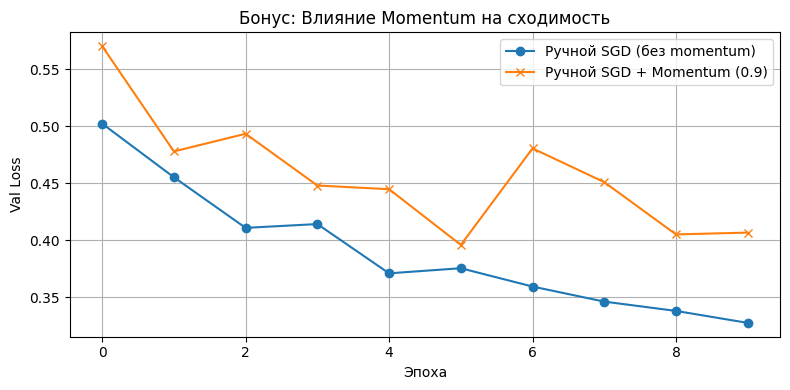

In [11]:
def train_epoch_manual_momentum(model, loader, loss_fn, lr, velocity, momentum=0.9):
    model.train()
    for xb, yb in loader:
        logits = model(xb)
        loss = loss_fn(logits, yb)
        model.zero_grad(set_to_none=True)
        loss.backward()
        with torch.no_grad():
            for p in model.parameters():
                if p.grad is not None:
                    velocity[p] = momentum * velocity[p] + p.grad
                    p -= lr * velocity[p]

# Сравнение чистого SGD и SGD + Momentum
set_seed()
m_sgd = build_model()
h_sgd = {"val_loss": []}
for _ in range(10):
    train_epoch_manual(m_sgd, train_loader, loss_fn, lr=best_lr)
    h_sgd["val_loss"].append(evaluate(m_sgd, val_loader, loss_fn, NUM_CLASSES)["loss"])

set_seed()
m_mom = build_model()
vel = {p: torch.zeros_like(p) for p in m_mom.parameters()}
h_mom = {"val_loss": []}
for _ in range(10):
    train_epoch_manual_momentum(m_mom, train_loader, loss_fn, best_lr, vel, momentum=0.9)
    h_mom["val_loss"].append(evaluate(m_mom, val_loader, loss_fn, NUM_CLASSES)["loss"])

plt.figure(figsize=(8, 4))
plt.plot(h_sgd["val_loss"], label="Ручной SGD (без momentum)", marker='o')
plt.plot(h_mom["val_loss"], label="Ручной SGD + Momentum (0.9)", marker='x')
plt.xlabel("Эпоха"); plt.ylabel("Val Loss"); plt.title("Бонус: Влияние Momentum на сходимость")
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

Анализ графика:

Чистый ручной SGD (синяя кривая): Демонстрирует стабильное монотонное снижение валидационной потери с 0.50 до ~0.33 за 9 эпох. Кривая плавная, без осцилляций — признак хорошо подобранного learning rate (lr=0.1) для данной задачи.

SGD + Momentum 0.9 (оранжевая кривая): Поведение контринтуитивное — вместо ускорения сходимости momentum ухудшил результат:

Конечный val loss ~0.41 против ~0.33 у чистого SGD (на ~24% хуже)

Сильные осцилляции throughout всего обучения (амплитуда ~0.08)

Начальный скачок с 0.57 вниз, затем нестабильное поведение

Объяснение эффекта:

При коэффициенте momentum β=0.9 эффективный learning rate возрастает приблизительно в 1/(1-β) = 10 раз:

   effective_lr ≈ lr / (1 - momentum) = 0.1 / 0.1 = 1.0

Значение 1.0 — критически велико для данной архитектуры. Именно поэтому:

Кривая momentum осциллирует (слишком большой эффективный шаг)

Сходимость хуже, чем у чистого SGD
Начальное значение выше (инерция на первых шагах работает против)

Практический вывод:

Momentum — не универсальное ускорение. При его добавлении необходимо одновременно уменьшать learning rate (обычно в 2-10 раз). В данном эксперименте lr=0.1 был оптимален для чистого SGD, но стал избыточным при β=0.9. Для корректного сравнения следовало бы использовать lr≈0.01 с momentum.